# Course Code: DT8013
# Course Name: Data Mining
# Lab Session: Anomaly Detection

### This lab is due on the 30/09/2026 at 23:59
### Save the notebook: 'yourname_lab_anomaly_detection.ipynb' and submit by the due date.



### Purpose of the Lab:
- Gain practical experience in applying anomaly detection techniques to real world data. 
- Analyze and evaluate the results of anomaly detection.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
pd.set_option("display.max_columns",100)
from IPython.display import Image
from sklearn.datasets import load_iris

## Anomaly Detection
A technique used to find patterns in a dataset that do not conform to the expected normal behaviour. These patterns are often called anomalies or outliers. The goal is to identify rare events or observations that are significantly different from the majority of the data.

<div class='alert alert-block alert-warning' style="font-weight:bolder">
 
 ### PyOD for Anomaly Detection

</div>

PyOD is a popular Python library specifically designed for anomaly detection tasks. It provides a comprehensive collection of algorithms, utilities, and evaluation metrics to help you identify anomalous data points in your datasets. You can read more here (https://pyod.readthedocs.io/en/latest/).

Key Features of PyOD:

- Diverse Algorithms: PyOD offers a wide range of outlier detection algorithms, including:
- Evaluation Metrics: PyOD provides various metrics to evaluate the performance of your outlier detection models, such as precision, recall, ROC and etc.
- Visualization Tools: The library includes functions for visualizing outlier detection results, helping you understand the performance of your models and identify potential outliers.
- Compatibility: PyOD is compatible with popular machine learning libraries like scikit-learn, making it easy to integrate with your existing workflows.
- To install pyod : use pip install pyod
- To import pyod: use import pyod

## Data overview

This dataset for this lab assignment consists of sensor data collected from an elderly care home, where seniors were living independently. The sensors recorded various environmental parameters, including temperature, humidity, CO2, CO, and MOX levels. Our objective is to identify the anomalous readings within the dataset.


In [3]:
elder_data=pd.read_csv('elderly_home.csv')
elder_data.head()

,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
0,20.64,55.57,121.0,496.0,521.0,694.0,652.0,591.0,135.0
1,20.64,55.53,122.0,495.0,521.0,694.0,652.0,591.0,135.0
2,20.62,55.53,121.0,495.0,522.0,694.0,651.0,591.0,135.0
3,20.62,55.57,121.0,495.0,522.0,694.0,651.0,591.0,135.0
4,20.62,55.59,121.0,495.0,522.0,694.0,652.0,591.0,135.0


In [4]:
elder_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 75511 entries, 0 to 75510
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   temperature    75511 non-null  float64
 1   humidity       75511 non-null  float64
 2   CO2CosIRValue  75511 non-null  float64
 3   CO2MG811Value  75511 non-null  float64
 4   MOX1           75511 non-null  float64
 5   MOX2           75511 non-null  float64
 6   MOX3           75511 non-null  float64
 7   MOX4           75511 non-null  float64
 8   COValue        75511 non-null  float64
dtypes: float64(9)
memory usage: 5.2 MB


<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task 1: Data Cleaning and Exploration (1pt)

- Clean and format the dataset as required.
- Conduct an initial exploration of the dataset, considering distributions, correlations, etc..

</div>

(75511, 9)
Missing Values:
 temperature      0
humidity         0
CO2CosIRValue    0
CO2MG811Value    0
MOX1             0
MOX2             0
MOX3             0
MOX4             0
COValue          0
dtype: int64

Duplicated:
 9889
Range and Distribution:



,count,mean,std,min,25%,50%,75%,max
temperature,75511.0,20.025767,1.404978,14.82,19.94,20.23,20.64,23.47
humidity,75511.0,56.690943,2.416317,46.27,55.36,57.03,58.31,69.26
CO2CosIRValue,75511.0,70.176226,22.969229,37.00,53.00,69.00,74.00,198.00
CO2MG811Value,75511.0,510.003523,9.233296,420.00,502.00,509.00,518.00,526.00
MOX1,75511.0,538.731390,21.364820,339.00,530.00,537.00,545.00,598.00
MOX2,75511.0,724.035849,19.940654,634.00,710.00,722.00,742.00,791.00
MOX3,75511.0,675.748619,22.754632,575.00,663.00,676.00,690.00,734.00
MOX4,75511.0,625.210473,27.964882,473.00,611.00,626.00,643.00,690.00
COValue,75511.0,114.237290,21.903941,82.00,101.00,109.00,120.00,918.00


Data Correleation:



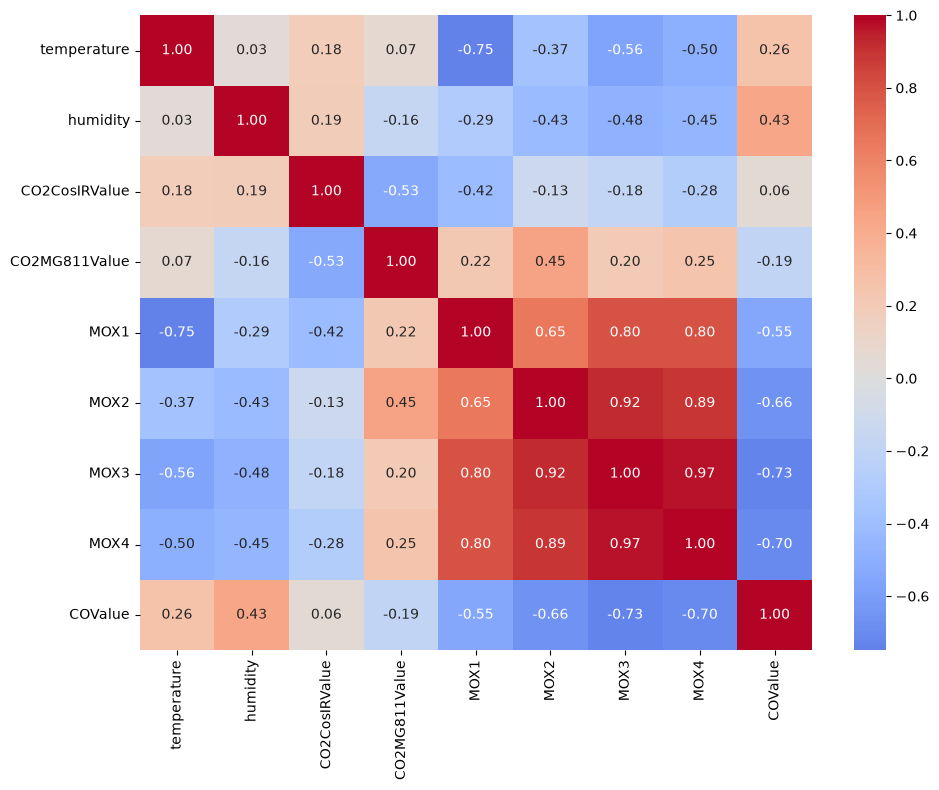

In [5]:
## YOUR CODE HERE

## Checking the data structure, missing values, and dulicates 
print(elder_data.shape)
print("Missing Values:\n",elder_data.isna().sum()) #see the missing values 
print("\nDuplicated:\n",elder_data.duplicated().sum())


# Ranges and distributions
print('Range and Distribution:\n')
display(elder_data.describe().T)


# Relationships between sensor readings
print('Data Correleation:\n')
plt.figure(figsize=(10, 8))
sns.heatmap(elder_data.corr(numeric_only=True), cmap="coolwarm",
            center=0, annot=True, fmt=".2f")
plt.tight_layout()
plt.show()

**Task 1 : Conclusion**
1. CO2CosIRValue : Maximum value(198) is much higher than the 75th percentile(74) -> Possible high value outlier 
2. COValue : Maximum value(918) is much higher than the 75th percentile(120) -> Possible high value outlier 
3. CO2MG811Value, MOX2, MOX3, MOX4 seems to be multimodal 
4. Temperature : is a left-skewed -> Few high value pull mean to to right 

### Heat map conclusion
1. MOX1 and MOX4  are strongly correlated (r=0.97)
2. COValue have -ve correlation with MOX datas 

### Possible further anamoly exploration data :
1. CO2CosIRValue 
2. C0Value 

<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 2: Anomaly Exploration (2pts)

- What types of anomalies do you expect to see in this dataset?
- Explore the data with various visualisations (e.g., scatter plots, histograms) to form a hypothesis about the nature of the anomalies.


 </div>

**Task 2 Answer: Expected Anamoly Type** 
1. **Univariate outliers:** COValue and CO2CosIRValue perhaps have high value outlier as their maximum(918 and 198) are far above the 75th percentile
2. **Mutivariate outliers:** MOX1 vs MOX4 as these snsors values are strongly correlated (r = 0.80), so normal readings should follow a clear trend. A point that falls far from that trend is abnormal as a *combination*, even if each value looks normal on its own. Similarly, a weakly correlated pair (`temperature` vs `humidity`, r = 0.03) can be used for comparision, as it has no trend to break. 
 


Histogram of data:



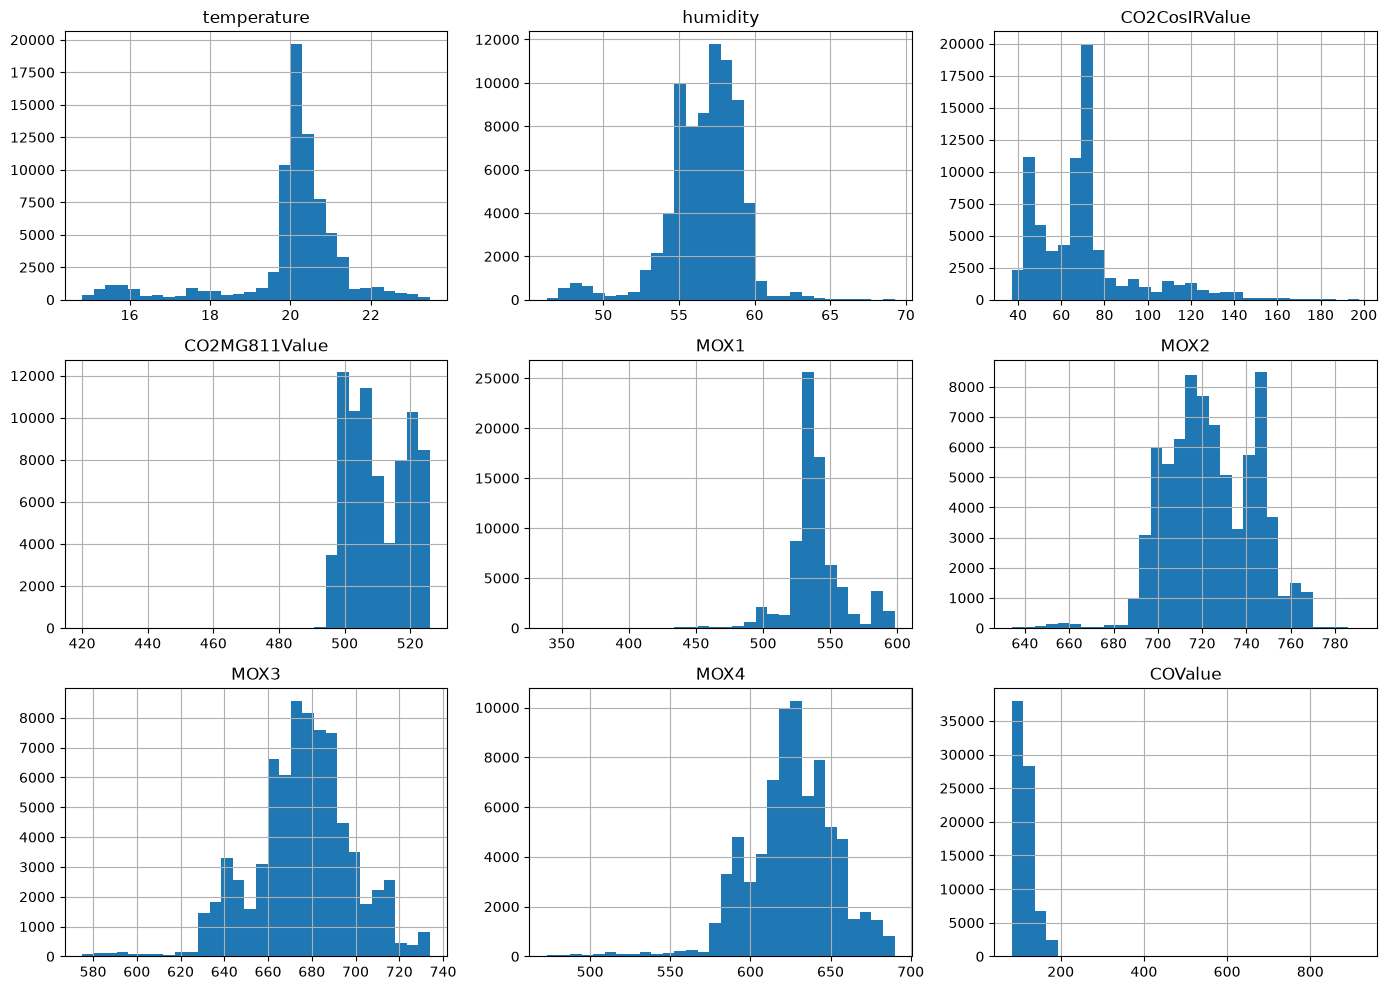

Box Plot of COVale and CO2cCosIRValue



C:\Users\sahbi\AppData\Local\Temp\ipykernel_56988\2101235080.py:27: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\University Doc\Course Content\Year2\Data Mining\Lab\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


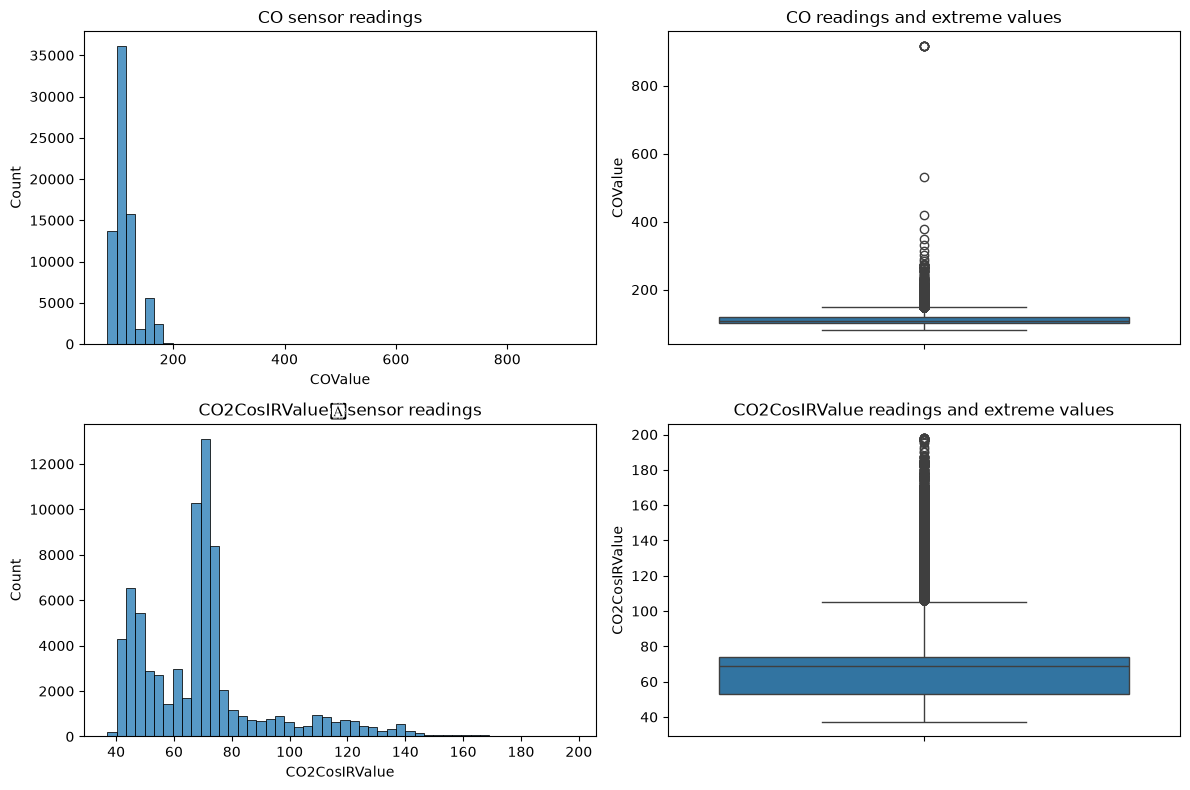

Scatter plot of strongest vs weakest



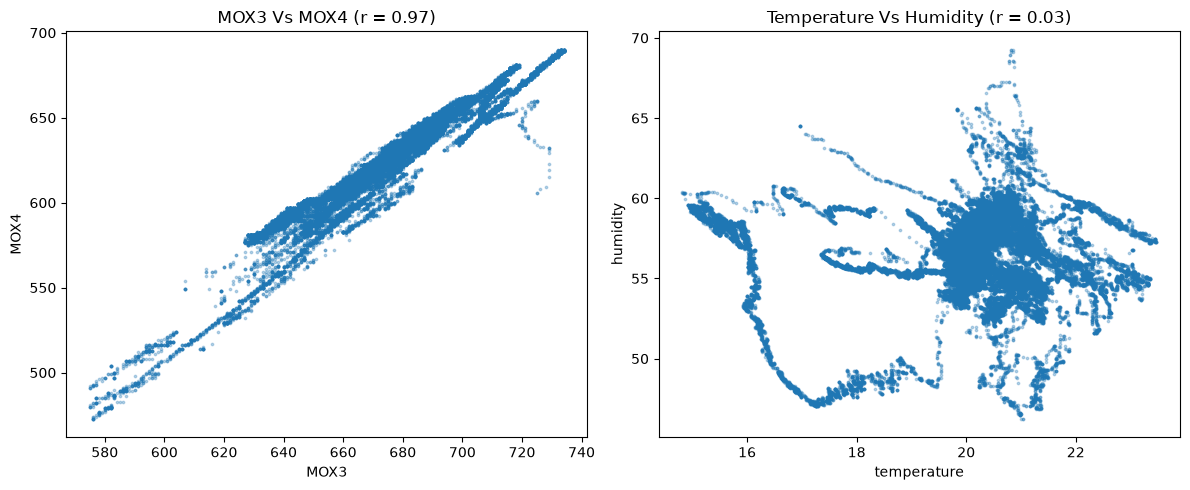

In [6]:
## YOUR CODE HERE


# 1. Data Histogram
print('Histogram of data:\n')
elder_data.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

#2. Box plot 
print('Box Plot of COVale and CO2cCosIRValue\n')
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=elder_data, x="COValue", bins=50, ax=axes[0, 0])
axes[0, 0].set_title("CO sensor readings")

sns.boxplot(data=elder_data, y="COValue", ax=axes[0, 1])
axes[0, 1].set_title("CO readings and extreme values")


sns.histplot(data=elder_data, x="CO2CosIRValue", bins=50, ax=axes[1, 0])
axes[1, 0].set_title("CO2CosIRValue	sensor readings")

sns.boxplot(data=elder_data, y="CO2CosIRValue", ax=axes[1, 1])
axes[1, 1].set_title("CO2CosIRValue readings and extreme values")

plt.tight_layout()
plt.show()

# 3. Scatter plots of feature pairs (strongest and weak correlations)
print('Scatter plot of strongest vs weakest\n')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(elder_data["MOX3"], elder_data["MOX4"], s=3, alpha=0.3)
axes[0].set(xlabel="MOX3", ylabel="MOX4", title="MOX3 Vs MOX4 (r = 0.97)")

axes[1].scatter(elder_data["temperature"], elder_data["humidity"], s=3, alpha=0.3)
axes[1].set(xlabel="temperature", ylabel="humidity", title="Temperature Vs Humidity (r = 0.03)")


plt.tight_layout()
plt.show()


<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 3: Anomaly Detection (2.5pts)

- Given the types of anomalies you expect, choose and implement at least three different unsupervised anomaly detection algorithms from the Lecture Notes 'Anomaly Detection 1'. 
- Justify your choices and explain why each method may be suited for the dataset


 </div>

#### Notice: In case you encountered ram overflow error, subsample the dataset randomly and conduct your analysis on the subsample.

```python
df_subsampled = df.sample(n = sample_size)
```

In [7]:
# An example

from pyod.models.hbos import HBOS #PYOD library

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

clf = HBOS() # Initialize model
clf.fit(df) # Fit the model

outliers = clf.predict(df) # Detect outliers
df['outliers'] = outliers
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),outliers
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,0
146,6.3,2.5,5.0,1.9,0
147,6.5,3.0,5.2,2.0,0
148,6.2,3.4,5.4,2.3,0


**Task 3 Answer : Choices of UNsupervised Anamoly detection algorithm**
1. **HBOS:** HBOS can handle extreme single sensor values like for COValue for instance at very fast 
2. **kNN:** kNN algorith can cathches globally isolated points, such as the points that break away from the MOX3/MOX4 diagonal. 
3. **LOF:** It can compare each points in its local neighborhood. The dense core and sparse trails in temperature vs humidity mean a global distance score would wrongly flag the trails, while LOF accounts for local density.

In [8]:
## YOUR CODE HERE
from pyod.models.hbos import HBOS
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from pyod.utils.utility import standardizer

# Drop duplicate rows as zero distances may confuse kNN and LOF
df = elder_data.drop_duplicates().reset_index(drop=True)

# Scale features so no sensor dominates the distances
X = standardizer(df)

models = {
    "HBOS": HBOS(n_bins=30, contamination=0.01),
    "kNN":  KNN(n_neighbors=20, contamination=0.01),
    "LOF":  LOF(n_neighbors=20, contamination=0.01),
}

results = df.copy()
for name, clf in models.items():
    clf.fit(X)
    results[f"{name}_score"] = clf.decision_scores_   # higher = more anomalous
    results[f"{name}_label"] = clf.labels_            # 1 = anomaly, 0 = normal
    print(f"{name}: {clf.labels_.sum()} anomalies flagged")

# Vote
label_cols = [f"{m}_label" for m in models]
print(results[label_cols].sum(axis=1).value_counts().sort_index())

HBOS: 657 anomalies flagged
kNN: 657 anomalies flagged
LOF: 657 anomalies flagged
0    63927
1     1437
2      240
3       18
Name: count, dtype: int64


<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 4: Anomaly Scores (2.5pts)

- The models can also output anomaly scores. Recall that higher scores are anomalies and lower scores are normal points.
- Plot these anomaly scores to visualise the distribution. How will you choose a threshold to classify a data point as an anomaly?
- Show this in the visualisation.


 </div>


HBOS: threshold 22.33, 469 anomalies (0.7%)
kNN: threshold 0.24, 5272 anomalies (8.0%)
LOF: threshold 1.18, 4716 anomalies (7.2%)
votes
0    56811
1     7244
2     1488
3       79
Name: count, dtype: int64


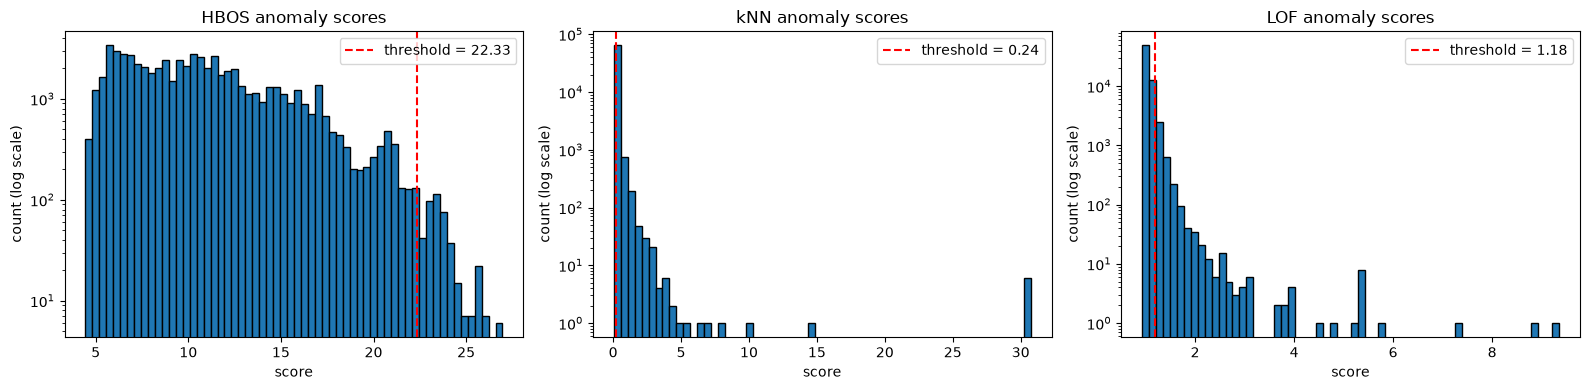

In [9]:
## YOUR CODE HERE
## 1. Using boxplot threshold for k =1.5
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, name in zip(axes, models):
    s = results[f"{name}_score"]
    q1, q3 = np.percentile(s, [25, 75])
    thr = q3 + 1.5 * (q3 - q1)                      # boxplot upper fence
    results[f"{name}_flag"] = (s > thr).astype(int) # new labels

    ax.hist(s, bins=60, log=True, edgecolor="k")
    ax.axvline(thr, color="red", ls="--", label=f"threshold = {thr:.2f}")
    ax.set(title=f"{name} anomaly scores", xlabel="score", ylabel="count (log scale)")
    ax.legend()
    print(f"{name}: threshold {thr:.2f}, {results[f'{name}_flag'].sum()} anomalies "
          f"({results[f'{name}_flag'].mean():.1%})")

# Votes
flag_cols = [f"{m}_flag" for m in models]
results["votes"] = results[flag_cols].sum(axis=1)
print(results["votes"].value_counts().sort_index())

plt.tight_layout()
plt.show()



In [10]:
# Comparing the threshold anomalies detection at k = 1.5 vs k = 3 
for m in models:
    s = results[f"{m}_score"]
    q1, q3 = np.percentile(s, [25, 75])
    for k in (1.5, 3):
        thr = q3 + k * (q3 - q1)
        print(f"{m}  k={k}: {(s > thr).sum()} anomalies ({(s > thr).mean():.1%})")

HBOS  k=1.5: 469 anomalies (0.7%)
HBOS  k=3: 0 anomalies (0.0%)
kNN  k=1.5: 5272 anomalies (8.0%)
kNN  k=3: 3071 anomalies (4.7%)
LOF  k=1.5: 4716 anomalies (7.2%)
LOF  k=3: 1743 anomalies (2.7%)


HBOS: threshold 21.76, 657 anomalies (1.0%)
kNN: threshold 0.75, 657 anomalies (1.0%)
LOF: threshold 1.43, 657 anomalies (1.0%)

Votes (how many models flagged each row):
votes
0    63927
1     1437
2      240
3       18
Name: count, dtype: int64


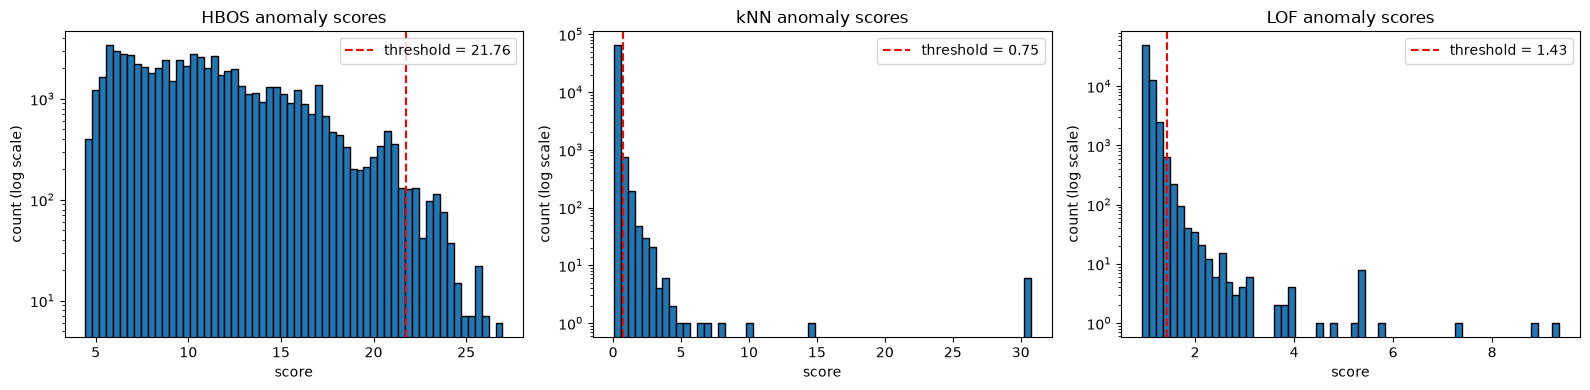

In [11]:
## 3. Using top 1% anomalies assumption
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, name in zip(axes, models):
    s = results[f"{name}_score"]
    thr = np.percentile(s, 99)                        # top 1% = anomalies
    results[f"{name}_flag"] = (s > thr).astype(int)   # new labels (overwrites the boxplot-rule flags)

    ax.hist(s, bins=60, log=True, edgecolor="k")
    ax.axvline(thr, color="red", ls="--", label=f"threshold = {thr:.2f}")
    ax.set(title=f"{name} anomaly scores", xlabel="score", ylabel="count (log scale)")
    ax.legend()
    print(f"{name}: threshold {thr:.2f}, {results[f'{name}_flag'].sum()} anomalies "
          f"({results[f'{name}_flag'].mean():.1%})")

# Votes
flag_cols = [f"{m}_flag" for m in models]
results["votes"] = results[flag_cols].sum(axis=1)
print("\nVotes (how many models flagged each row):")
print(results["votes"].value_counts().sort_index())


plt.tight_layout()
plt.show()



**Task 4: Anomaly Scores Answers**

**Score distributions.** I plotted the anomaly scores of the three models as
histograms (log y-axis). It was found that for kNN and LOF, almost all rows lie in one very narrow
block of low scores, followed by a thin, discontinuous tail with isolated points
far to the right (e.g. a small group near 30 for kNN). HBOS scores form a broad,
smooth decline with no clear separation between normal and abnormal points.

**Selecting threshold** Initially I choosed boxplot rule for threshold, as it is data driven, need no assumption about anamoly rate and is robust to the skewed score distribution. Threshold model's score was set as :
threshold = Q3 + 1.5 × IQR.
However, something was catchy, the anamoly detection by kNN and LOF was almost 8% and 7.2% respectivelt, which doesn't seems to satisfy the data spreading. The reason I believe is the discontinous tail with far isolated points as can be seen in the figure of task 4. 

Thus I tried by increasing the multiplier from 1.5 to 3 and compare them, and the result shown below in the table. but doing so , HBOS drops to zero while kNN and LOF still flaged higher. 

| Rule | HBOS | kNN | LOF |
|---|---|---|---|
| Boxplot, Q3 + 1.5×IQR | 469 (0.7%) | 5,272 (8.0%) | 4,716 (7.2%) |
| Boxplot, Q3 + 3×IQR | 0 (0.0%) | 3,071 (4.7%) | 1,743 (2.7%) |
| 99th percentile | 657 (1.0%) | 657 (1.0%) | 657 (1.0%) |


**Decision:** At last, I calculated the 99th percentile asssumption that gives a small and comparable anomaly set. This seems more practical here because the quartile rule works fine if the data would have been roughly symmetric or moderate skewed but the score distribution are strongly skewed thus the rule becomes too sensitive for some models and too insensitives for others. However, it's limitation is that the 1% rate is as an assumption rather than something estimated from the data 


<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 5: Interpretation (2pts)

- For the top 10 anomalies identified by your models, can you interpret why they were flagged?
- You can visualise the anomalies in relation to the normal data to provide a clear explanation.

 </div>

,COValue,CO2CosIRValue,temperature,humidity,MOX1,MOX2,MOX3,MOX4,votes,avg_score_rank
32133,918.0,94.0,16.97,64.51,364.0,790.0,725.0,606.0,3,0.99
32134,918.0,96.0,16.97,64.51,364.0,791.0,725.0,606.0,3,0.99
32135,918.0,96.0,16.97,64.51,364.0,791.0,726.0,608.0,3,0.99
32136,918.0,98.0,16.97,64.51,364.0,791.0,728.0,609.0,3,0.99
32137,918.0,99.0,16.97,64.51,364.0,791.0,729.0,615.0,3,0.97
32138,918.0,99.0,16.97,64.51,364.0,791.0,729.0,619.0,3,0.96
32139,532.0,99.0,17.05,63.98,376.0,791.0,729.0,623.0,3,0.95
32140,420.0,99.0,17.07,63.98,383.0,790.0,729.0,629.0,3,0.93
32141,377.0,99.0,17.12,63.92,394.0,790.0,729.0,631.0,3,0.91
32142,348.0,100.0,17.18,63.88,400.0,790.0,729.0,632.0,3,0.87


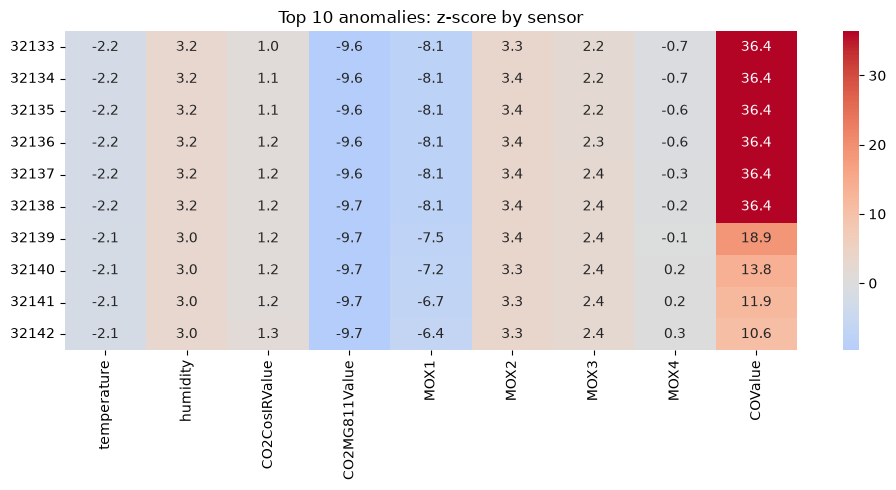

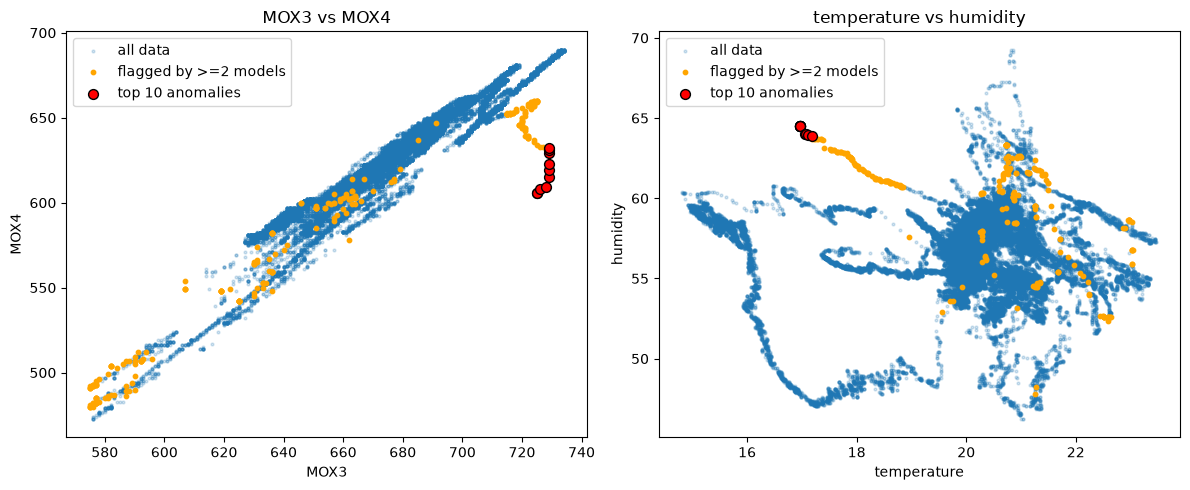

In [13]:
# Your code here

# 1. Anomaly flags definition using a threshold
for name in models:
    threshold = np.percentile(results[f"{name}_score"], 99)
    results[f"{name}_flag"] = (results[f"{name}_score"] > threshold).astype(int)

# 2. Majority vote across models
flag_cols = [f"{m}_flag" for m in models]
results["votes"] = results[flag_cols].sum(axis=1)

# Only rows flagged by at least 2 models
flagged = results[results["votes"] >= 2].copy()

# 3. Anamolous logs ranks
score_cols = [f"{m}_score" for m in models]
flagged["avg_score_rank"] = flagged[score_cols].rank(pct=True).mean(axis=1)

top10 = (
    flagged
    .sort_values("avg_score_rank", ascending=False)
    .head(10)
)

display(top10[["COValue", "CO2CosIRValue", "temperature", "humidity",
               "MOX1", "MOX2", "MOX3", "MOX4", "votes", "avg_score_rank"]].round(2))

# 4. top 10 anomalies in z-score form
z_scores = (df - df.mean()) / df.std()
top10_z = z_scores.loc[top10.index]

plt.figure(figsize=(10, 5))
sns.heatmap(top10_z, cmap="coolwarm", center=0, annot=True, fmt=".1f")
plt.title("Top 10 anomalies: z-score by sensor")
plt.tight_layout()
plt.show()

# # 5. Print interpretation for each top anomaly
# for idx, row in top10_z.iterrows():
#     top3 = row.abs().sort_values(ascending=False).head(3)
#     print(f"Row {idx}:")
#     for sensor, z in top3.items():
#         print(f"  {sensor}: {z:+.1f}σ")
#     print()

# 6. Visualization of anomalies against normal data
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pairs = [("MOX3", "MOX4"), ("temperature", "humidity")]

for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df[x], df[y], s=4, alpha=0.2, label="all data")
    ax.scatter(flagged[x], flagged[y], s=10, c="orange", label="flagged by >=2 models")
    ax.scatter(top10[x], top10[y], s=50, c="red", edgecolor="k", label="top 10 anomalies")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.legend()
    ax.set_title(f"{x} vs {y}")

plt.tight_layout()
plt.show()

**Task 5 answers:** The top 10 anomalies were identified by combining the outputs of the three unsupervised models i.e HBOS, kNN, and LOF. I used a consensus rule where a row was considered anomalous if it was flagged by at least two out of the three models. 

After selecting the top 10 most anomalies, I inspected their sensor values. These anomalies were mostly explained by abnormal COValue and CO2CosIRValue sensors because the dataset shows that their values contain extreme high values compared with the rest of the population. In several cases, the flagged rows also deviated from the typical relationship between MOX sensors, which suggests a multivariate anomaly rather than a simple univariate outlier.

This means that the anomalies are not only “very high” values but also “unexpected” combinations of environmental conditions. For example, a point may have normal MOX readings individually, but when considered together with the surrounding data it is far from the normal trend. That is why LOF and kNN are useful here.